<a href="https://colab.research.google.com/github/Swathims1/BIS-LAB/blob/main/Cuckoo_Search_Week05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


JOB ALLOCATION
-------------------------
Job 1 -> Processor 1 | Execution: 10 | Transfer: 2
Job 2 -> Processor 2 | Execution: 9 | Transfer: 2
Job 3 -> Processor 3 | Execution: 10 | Transfer: 2
Job 4 -> Processor 2 | Execution: 7 | Transfer: 1
Job 5 -> Processor 3 | Execution: 6 | Transfer: 2
Job 6 -> Processor 1 | Execution: 6 | Transfer: 2

PROCESSOR LOADS
Processor 1 : 16.0
Processor 2 : 16.0
Processor 3 : 16.0

Makespan: 16.0
Total Transfer Time: 11
Load Imbalance: 0.0
Fitness: 18.2

EXACT GLOBAL OPTIMUM
-------------------------

JOB ALLOCATION
-------------------------
Job 1 -> Processor 2 | Execution: 8 | Transfer: 3
Job 2 -> Processor 1 | Execution: 7 | Transfer: 1
Job 3 -> Processor 2 | Execution: 6 | Transfer: 1
Job 4 -> Processor 1 | Execution: 8 | Transfer: 2
Job 5 -> Processor 3 | Execution: 6 | Transfer: 2
Job 6 -> Processor 3 | Execution: 7 | Transfer: 1

PROCESSOR LOADS
Processor 1 : 15.0
Processor 2 : 14.0
Processor 3 : 13.0

Makespan: 15.0
Total Transfer Time: 10
Load

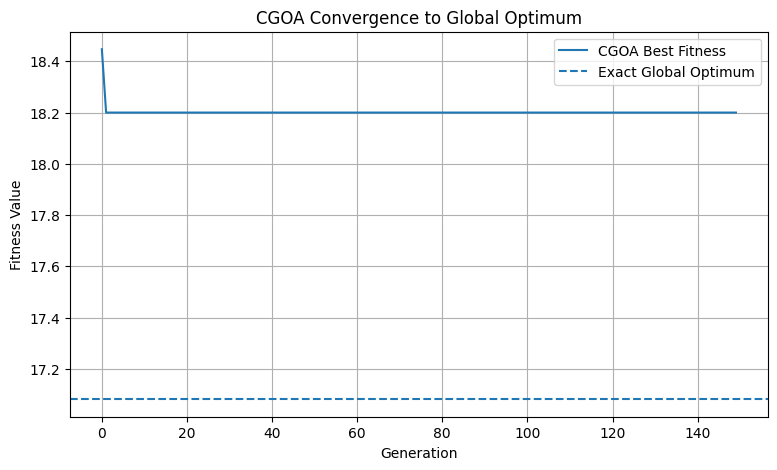

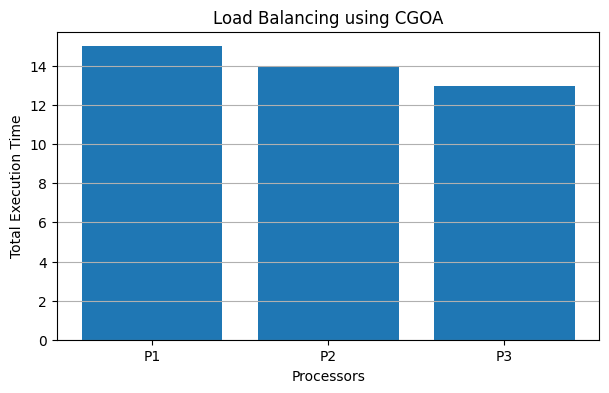

In [1]:

import random
import numpy as np
import matplotlib.pyplot as plt
from itertools import product

# Job execution time on each processor
execution = np.array([
    [10, 8, 12],
    [ 7, 9, 11],
    [12, 6, 10],
    [ 8, 7,  9],
    [ 9,11,  6],
    [ 6, 8,  7]
])

# Transfer time of each job on each processor
transfer = np.array([
    [2, 3, 1],
    [1, 2, 3],
    [3, 1, 2],
    [2, 1, 3],
    [1, 3, 2],
    [2, 2, 1]
])

JOBS, MACHINES = execution.shape

POP_SIZE = 30
GENERATIONS = 150
random.seed(42)
np.random.seed(42)

# Fitness calculation
def fitness(chromosome):

    loads = np.zeros(MACHINES)
    total_transfer = 0

    for job, machine in enumerate(chromosome):
        loads[machine] += execution[job][machine]
        total_transfer += transfer[job][machine]

    makespan = max(loads)
    imbalance = np.std(loads)

    return makespan + 0.2 * total_transfer + 0.1 * imbalance


# Create initial population
population = [
    np.random.randint(0, MACHINES, JOBS)
    for _ in range(POP_SIZE)
]

best_history = []

# CGOA algorithm
for generation in range(GENERATIONS):

    # Cuckoo Search Phase
    population.sort(key=fitness)

    new_population = []

    for cuckoo in population:

        new_cuckoo = cuckoo.copy()

        # Move cuckoo towards the best solution
        for j in range(JOBS):

            if random.random() < 0.35:
                new_cuckoo[j] = population[0][j]

            if random.random() < 0.15:
                new_cuckoo[j] = random.randint(0, MACHINES - 1)

        new_population.append(new_cuckoo)

    population.extend(new_population)

    # Keep best nests
    population.sort(key=fitness)
    population = population[:POP_SIZE]

    # Genetic Algorithm Phase
    children = []

    for _ in range(POP_SIZE // 2):

        # Selection
        p1, p2 = random.sample(population[:15], 2)

        # One-point crossover
        point = random.randint(1, JOBS - 1)

        child1 = np.concatenate((p1[:point], p2[point:]))
        child2 = np.concatenate((p2[:point], p1[point:]))

        # Mutation
        for child in [child1, child2]:
            if random.random() < 0.4:
                position = random.randint(0, JOBS - 1)
                child[position] = random.randint(0, MACHINES - 1)

            children.append(child)

    population.extend(children)
    population.sort(key=fitness)
    population = population[:POP_SIZE]

    best_history.append(fitness(population[0]))

# Best CGOA solution
best_solution = population[0]

# Calculate scheduling details
def show_result(solution):

    loads = np.zeros(MACHINES)
    total_transfer = 0

    print("\nJOB ALLOCATION")
    print("-------------------------")

    for job, machine in enumerate(solution):

        time = execution[job][machine]
        trans = transfer[job][machine]

        loads[machine] += time
        total_transfer += trans

        print("Job", job + 1,
              "-> Processor", machine + 1,
              "| Execution:", time,
              "| Transfer:", trans)

    makespan = max(loads)
    imbalance = np.std(loads)

    print("\nPROCESSOR LOADS")
    for i in range(MACHINES):
        print("Processor", i + 1, ":", loads[i])

    print("\nMakespan:", makespan)
    print("Total Transfer Time:", total_transfer)
    print("Load Imbalance:", round(imbalance, 2))
    print("Fitness:", round(fitness(solution), 2))

show_result(best_solution)

# Find exact global optimum for this small problem
all_solutions = product(range(MACHINES), repeat=JOBS)

global_solution = min(all_solutions, key=fitness)

print("\nEXACT GLOBAL OPTIMUM")
print("-------------------------")
show_result(global_solution)

# Compare CGOA and exact optimum
print("\nCGOA Fitness:", round(fitness(best_solution), 2))
print("Global Optimum Fitness:", round(fitness(global_solution), 2))

# Convergence graph
plt.figure(figsize=(9, 5))
plt.plot(best_history, label="CGOA Best Fitness")
plt.axhline(fitness(global_solution),
            linestyle="--", label="Exact Global Optimum")

plt.xlabel("Generation")
plt.ylabel("Fitness Value")
plt.title("CGOA Convergence to Global Optimum")
plt.legend()
plt.grid()
plt.show()

# Processor load graph
loads = np.zeros(MACHINES)

for job, machine in enumerate(global_solution):
    loads[machine] += execution[job][machine]

plt.figure(figsize=(7, 4))
plt.bar(
    ["P1", "P2", "P3"],
    loads
)
plt.xlabel("Processors")
plt.ylabel("Total Execution Time")
plt.title("Load Balancing using CGOA")
plt.grid(axis="y")
plt.show()
